# 01b - Add labeled conflicts to the pilot dataset

Does **not** change `pilot_v1.zip` or notebook 01. It only writes two new metadata files next to the zip, reusing the existing images (no image copies, runs on CPU in about a minute):

- `metadata_conflicts.jsonl`: conflict rows only
- `metadata_with_conflicts.jsonl`: original rows + conflict rows

Each conflict row keeps its base photo's split (train / val / test), so there is no leakage across splits.

| `conflict_type` | What conflicts | How it is made |
|---|---|---|
| `object_text_sketch` | caption vs sketch (what the object is) | caption from another category in the same split |
| `color_text_ref` | caption vs reference (color) | caption color changed to one that is not in `ref_colors` |
| `material_text_ref` | caption vs reference (material) | material phrase that contradicts `ref_material` |
| `appearance_ref_swap` | whole appearance of reference vs caption | reference (and its `ref_*` fields) taken from another row with different colors |

New fields: `original_id`, `conflict_type`, `conflict_attr`, `conflict_between`, `expected_resolution`, `caption_category`, `conflict_detail`.
Policy used everywhere: geometry from the sketch, appearance from the reference, wording from the text. Edit `RESOLUTION` below if your team decides differently.

In [1]:
DRIVE_ROOT = "/content/drive/MyDrive/sketchy_dataset_one_sketch"
ZIP_PATH = f"{DRIVE_ROOT}/pilot_v1.zip"
LOCAL_DATA = "/content/pilot_v1"
PER_TYPE = 1          # conflict rows of each type per photo (1 -> 4 conflict rows per photo)
SEED = 0

RESOLUTION = {
    "object_text_sketch":  "keep the sketch outline; do not turn the object into the one named in the caption",
    "color_text_ref":      "take color from the reference, not the caption; keep the sketch geometry",
    "material_text_ref":   "take material from the reference, not the caption; keep the sketch geometry",
    "appearance_ref_swap": "take color/material/finish from the swapped reference; do not copy its object shape",
}

In [2]:
from google.colab import drive
drive.mount("/content/drive")
import json, zipfile, glob, os, re, random, hashlib
from collections import Counter, defaultdict

if not glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True):
    os.makedirs(LOCAL_DATA, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL_DATA)
meta_path = glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True)[0]
DATA_DIR = os.path.dirname(meta_path)
base_rows = [json.loads(l) for l in open(meta_path) if l.strip()]
print("original rows:", len(base_rows), Counter(r["split"] for r in base_rows))
print("conflict_type in v1:", Counter(r["conflict_type"] for r in base_rows))

Mounted at /content/drive
original rows: 200 Counter({'train': 160, 'val': 20, 'test': 20})
conflict_type in v1: Counter({'none': 200})


In [3]:
COLORS = ["red", "blue", "green", "yellow", "orange", "purple", "pink", "black", "white", "brown", "gray", "silver", "gold", "beige"]
MATERIALS = [("wooden", "wood"), ("metal", "metal"), ("plastic", "plastic"), ("ceramic", "ceramic"),
             ("glass", "glass"), ("leather", "leather"), ("fabric", "fabric"), ("stone", "stone")]
ABBR = {"object_text_sketch": "sem", "color_text_ref": "clr", "material_text_ref": "mat", "appearance_ref_swap": "app"}
REF_FIELDS = ["reference", "ref_colors", "ref_material", "ref_finish", "ref_object", "ref_prompt"]
TOK = lambda s: set(re.findall(r"[a-z]+", str(s).lower()))

def rng_for(*parts):
    return random.Random(int(hashlib.md5("|".join(map(str, (SEED,) + parts)).encode()).hexdigest()[:8], 16))

def base_conflict(base, ctype):
    r = dict(base)
    r.update(id=f"{base['id']}_{ABBR[ctype]}", original_id=base["id"], conflict_type=ctype,
             expected_resolution=RESOLUTION[ctype], caption_category=base["category"],
             geometry_src="sketch", semantics_src="text", appearance_src="reference")
    return r

def make_sem(base, pool, rng):
    cands = [p for p in pool if p["category"] != base["category"]]
    if not cands: return None
    p = rng.choice(cands)
    r = base_conflict(base, "object_text_sketch")
    r.update(caption=p["caption"], caption_category=p["category"], conflict_attr="object", conflict_between=["text", "sketch"],
             conflict_detail={"caption_from": p["id"], "caption_object": p["category"], "sketch_object": base["category"]})
    return r

def make_color(base, pool, rng):
    avoid = TOK(base["ref_colors"]) | TOK(base["caption"])
    options = [c for c in COLORS if c not in avoid]
    new = rng.choice(options)
    cap = base["caption"]
    present = [c for c in COLORS if re.search(rf"\b{c}\b", cap, re.I)]
    if present:
        cap2 = re.sub(rf"\b{present[0]}\b", new, cap, count=1, flags=re.I)
        if cap[:1].isupper(): cap2 = cap2[:1].upper() + cap2[1:]
    else:
        cap2 = cap.rstrip(".") + f", {new}."
    r = base_conflict(base, "color_text_ref")
    r.update(caption=cap2, conflict_attr="color", conflict_between=["text", "reference"],
             conflict_detail={"caption_color": new, "ref_colors": base["ref_colors"]})
    return r

def make_material(base, pool, rng):
    ref_m = str(base["ref_material"]).lower()
    options = [(a, s) for a, s in MATERIALS if s not in ref_m and s[:4] not in ref_m]
    adj, _ = rng.choice(options)
    cap = base["caption"]
    present = [a for a, _ in MATERIALS if re.search(rf"\b{a}\b", cap, re.I)]
    if present:
        cap2 = re.sub(rf"\b{present[0]}\b", adj, cap, count=1, flags=re.I)
    else:
        cap2 = cap.rstrip(".") + f", made of {adj.replace('wooden', 'wood')}."
    r = base_conflict(base, "material_text_ref")
    r.update(caption=cap2, conflict_attr="material", conflict_between=["text", "reference"],
             conflict_detail={"caption_material": adj, "ref_material": base["ref_material"]})
    return r

def make_app(base, pool, rng):
    cands = [p for p in pool if p["id"] != base["id"] and TOK(p["ref_colors"]).isdisjoint(TOK(base["ref_colors"]))]
    cands = cands or [p for p in pool if p["id"] != base["id"] and p["ref_colors"] != base["ref_colors"]]
    if not cands: return None
    p = rng.choice(cands)
    r = base_conflict(base, "appearance_ref_swap")
    for k in REF_FIELDS: r[k] = p[k]
    r.update(ref_dino_sim=None, ref_color_dist=None, ref_filters_passed=None,
             conflict_attr="appearance", conflict_between=["reference", "text"],
             conflict_detail={"reference_from": p["id"], "ref_colors": p["ref_colors"], "target_ref_colors": base["ref_colors"]})
    return r

MAKERS = {"object_text_sketch": make_sem, "color_text_ref": make_color, "material_text_ref": make_material, "appearance_ref_swap": make_app}

by_split = defaultdict(list)
for r in base_rows: by_split[r["split"]].append(r)

conflicts = []
for split, pool in by_split.items():
    for base in pool:
        for ctype, fn in MAKERS.items():
            for k in range(PER_TYPE):
                row = fn(base, pool, rng_for(base["id"], ctype, k))
                if row is not None:
                    if k > 0: row["id"] += f"_{k}"
                    conflicts.append(row)

print("conflict rows:", len(conflicts))
print(Counter((r["split"], r["conflict_type"]) for r in conflicts))

conflict rows: 800
Counter({('train', 'object_text_sketch'): 160, ('train', 'color_text_ref'): 160, ('train', 'material_text_ref'): 160, ('train', 'appearance_ref_swap'): 160, ('val', 'object_text_sketch'): 20, ('val', 'color_text_ref'): 20, ('val', 'material_text_ref'): 20, ('val', 'appearance_ref_swap'): 20, ('test', 'object_text_sketch'): 20, ('test', 'color_text_ref'): 20, ('test', 'material_text_ref'): 20, ('test', 'appearance_ref_swap'): 20})


In [4]:
with open(f"{DRIVE_ROOT}/metadata_conflicts.jsonl", "w") as f:
    for r in conflicts: f.write(json.dumps(r) + "\n")
with open(f"{DRIVE_ROOT}/metadata_with_conflicts.jsonl", "w") as f:
    for r in base_rows + conflicts: f.write(json.dumps(r) + "\n")
print("written:", f"{DRIVE_ROOT}/metadata_conflicts.jsonl", "and metadata_with_conflicts.jsonl")

# every referenced file must exist in the v1 zip layout
missing = [(r["id"], k) for r in conflicts for k in ("target", "sketch", "reference", "mask") if not os.path.exists(os.path.join(DATA_DIR, r[k]))]
print("missing files:", len(missing), missing[:5])

written: /content/drive/MyDrive/sketchy_dataset_one_sketch/metadata_conflicts.jsonl and metadata_with_conflicts.jsonl
missing files: 0 []


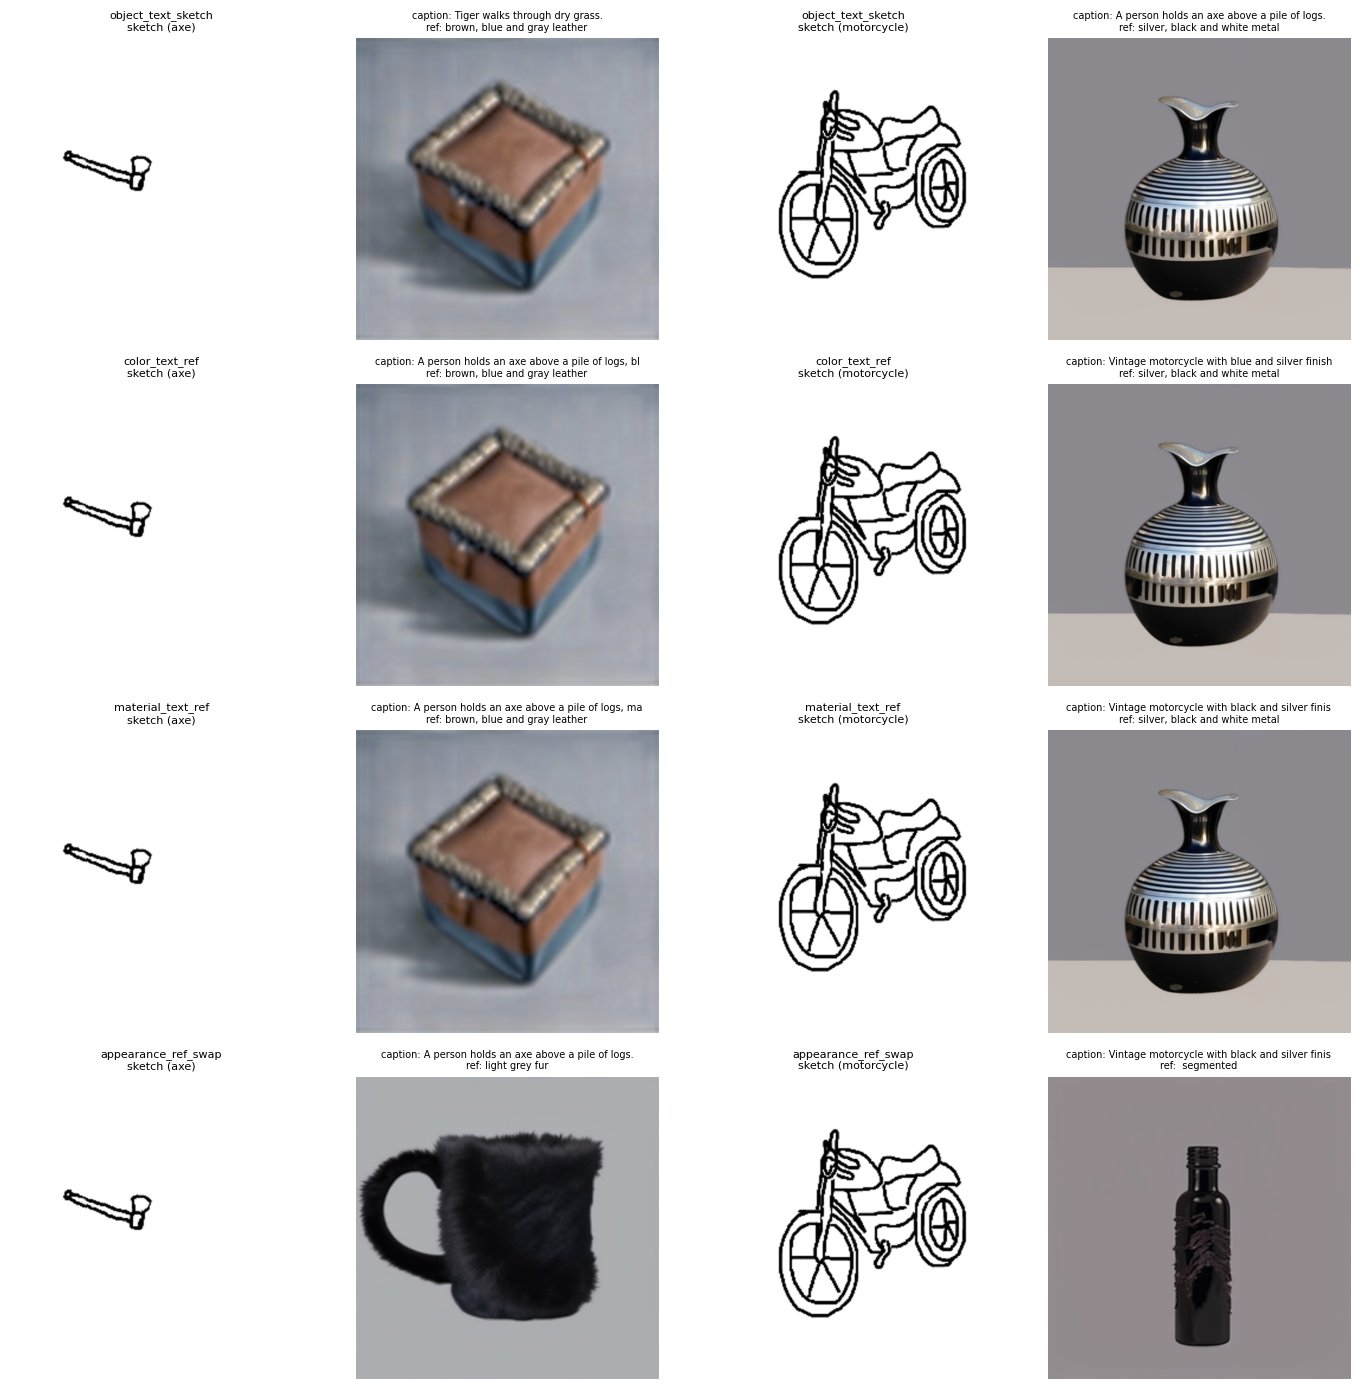

object_text_sketch     | before: 'Blue-handled hammer with wooden handle.'  ->  after: 'A person holds a shiny, silver French horn.' | ref: blue and white, plastic
color_text_ref         | before: 'Blue-handled hammer with wooden handle.'  ->  after: 'Pink-handled hammer with wooden handle.' | ref: blue and white, plastic
material_text_ref      | before: 'Blue-handled hammer with wooden handle.'  ->  after: 'Blue-handled hammer with stone handle.' | ref: blue and white, plastic
appearance_ref_swap    | before: 'Blue-handled hammer with wooden handle.'  ->  after: 'Blue-handled hammer with wooden handle.' | ref: grey, solid


In [5]:
import matplotlib.pyplot as plt
from PIL import Image
fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for i, ctype in enumerate(MAKERS):
    ex = [r for r in conflicts if r["conflict_type"] == ctype and r["split"] == "test"][:2]
    for j, r in enumerate(ex):
        ax[i, 2 * j].imshow(Image.open(os.path.join(DATA_DIR, r["sketch"]))); ax[i, 2 * j].set_title(f"{ctype}\nsketch ({r['category']})", fontsize=8)
        ax[i, 2 * j + 1].imshow(Image.open(os.path.join(DATA_DIR, r["reference"])))
        ax[i, 2 * j + 1].set_title(("caption: " + r["caption"])[:55] + "\nref: " + str(r["ref_colors"]) + " " + str(r["ref_material"]), fontsize=7)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
for ctype in MAKERS:
    r = next(r for r in conflicts if r["conflict_type"] == ctype)
    b = next(b for b in base_rows if b["id"] == r["original_id"])
    print(f"{ctype:22s} | before: {b['caption']!r}  ->  after: {r['caption']!r} | ref: {r['ref_colors']}, {r['ref_material']}")